In [ ]:
lazy import pandas as pd
lazy import numpy as np
lazy import matplotlib.pyplot as plt
lazy import seaborn as sns

lazy from sklearn.model_selection import train_test_split
lazy from sklearn.preprocessing import StandardScaler
lazy from sklearn.linear_model import LinearRegression
lazy from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


print("All Important Library are imported Successfully!!")

All Important Library are imported Successfully!!


In [ ]:
df = pd.read_csv('../data/processed/df.csv')
print("Dataset loaded successfulyy!")

Dataset loaded successfulyy!


In [59]:
df.shape

(9873, 6)

In [46]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [47]:
num_col = df.select_dtypes(include=['number']).columns.tolist()
cat_col = df.select_dtypes(include=['object','bool','category']).columns.tolist()

C:\Users\shekh\AppData\Local\Temp\ipykernel_14972\1657010385.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_col = df.select_dtypes(include=['object','bool','category']).columns.tolist()


## 4. Univariate Analysis

### Objective

To understand the distribution, frequency, and variability of individual numerical features using histograms.

### Key Observations

1. **Hours Studied:** The feature contains discrete values ranging approximately from 1 to 9 hours. The observed frequencies are relatively similar across categories.

2. **Previous Scores:** Scores range approximately from 40 to 100. The distribution shows variation across score intervals without an obvious strong skew.

3. **Sleep Hours:** Values range approximately from 4 to 9 hours, with relatively balanced frequencies across the observed categories.

4. **Sample Question Papers Practiced:** The feature ranges approximately from 0 to 9. Its distribution appears relatively balanced across categories.

5. **Performance Index:** The distribution is broadly bell-shaped, with more observations in the middle range and fewer observations near the extremes.

### Conclusion

The histograms provide an initial understanding of the numerical features and their distributions. Further analysis is required to investigate relationships between features, identify potential outliers, and understand which variables are associated with the target.

These observations are preliminary and should be verified using descriptive statistics and subsequent analyses.


### Target Variable Distribution

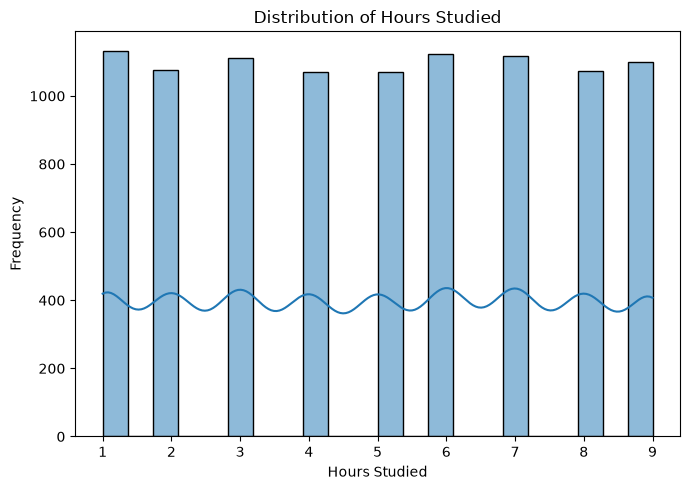

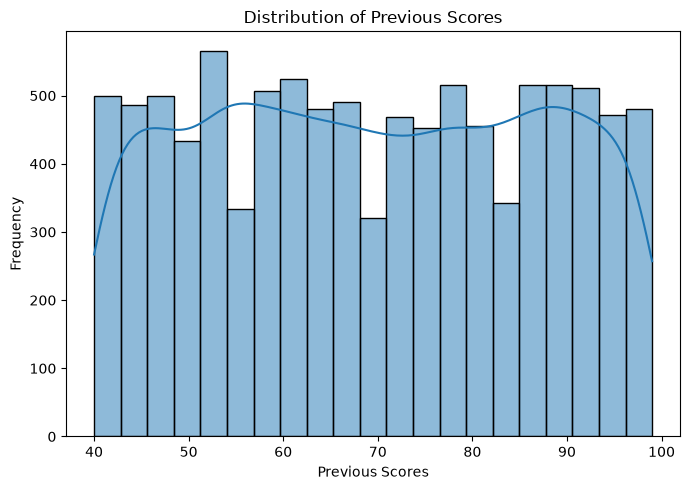

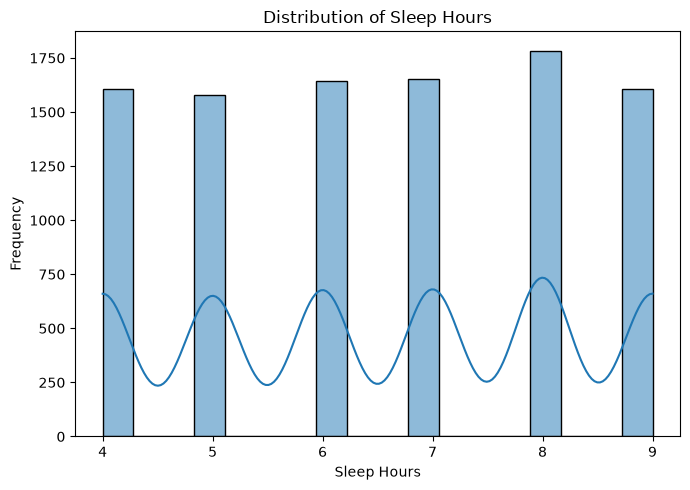

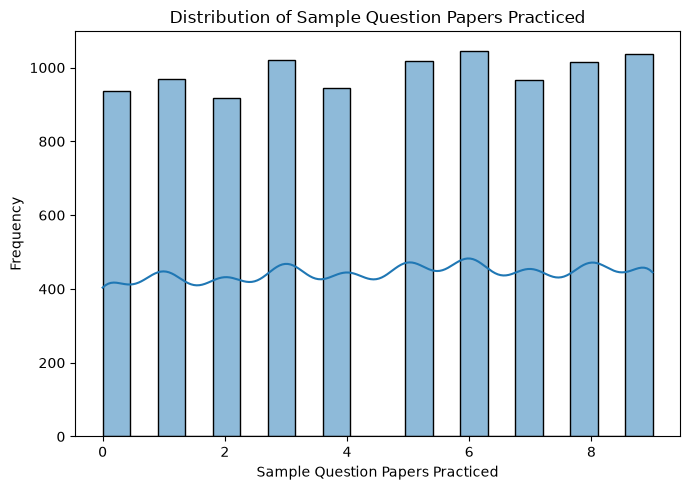

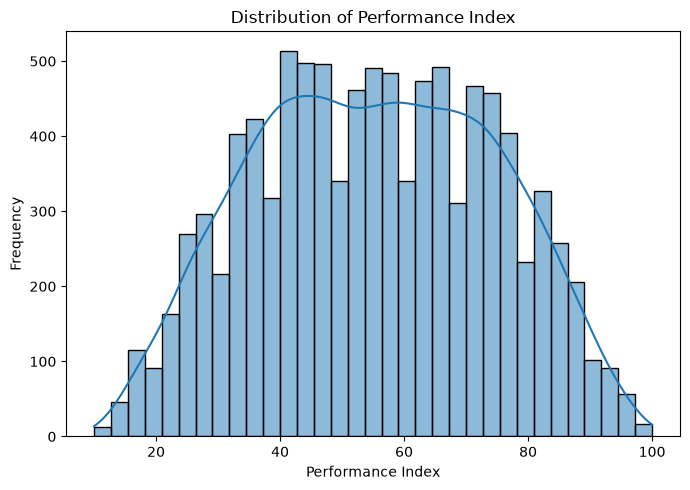

In [48]:
for col in num_col:
    plt.figure(figsize=(7,5))
    sns.histplot(data=df,x=col,kde=True)
    
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()


## 5. Bivariate Analysis

### Objective
To investigate the relationships between individual input features
and the target variable, Performance Index.

### 5.1 Numerical Features vs Performance Index
Scatter plots are used to visualize relationships between
numerical features and the target variable.

In [49]:
target = 'Performance Index'
features = ['Hours Studied','Previous Scores','Extracurricular Activities','Sleep Hours','Sample Question Papers Practiced']
target


'Performance Index'

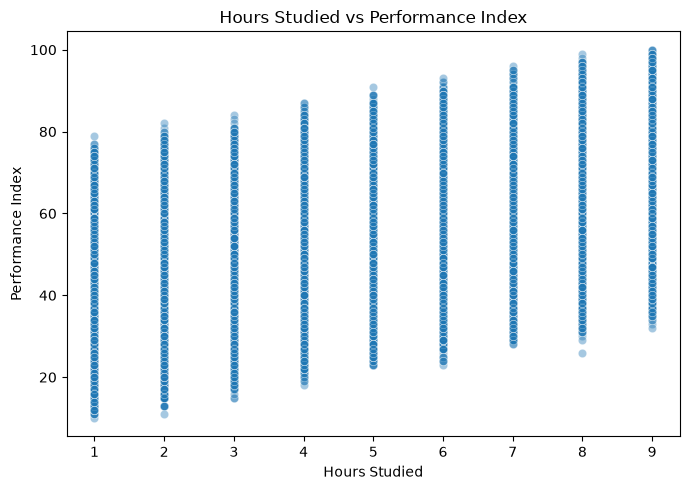

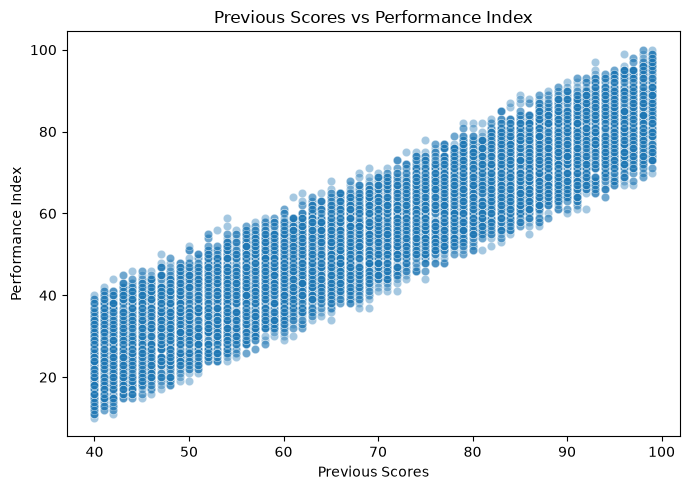

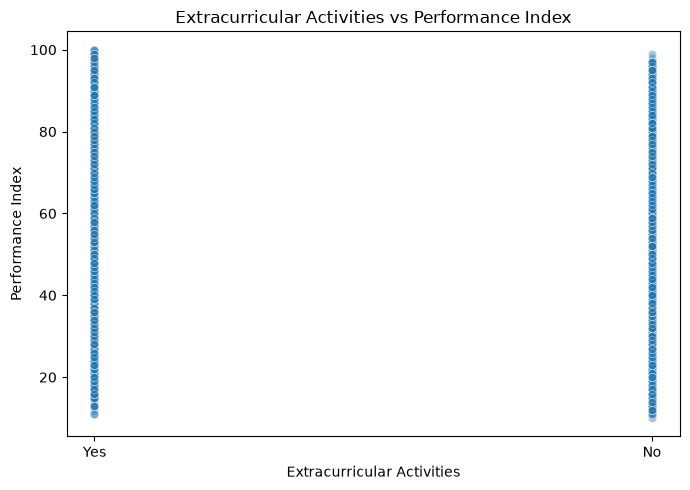

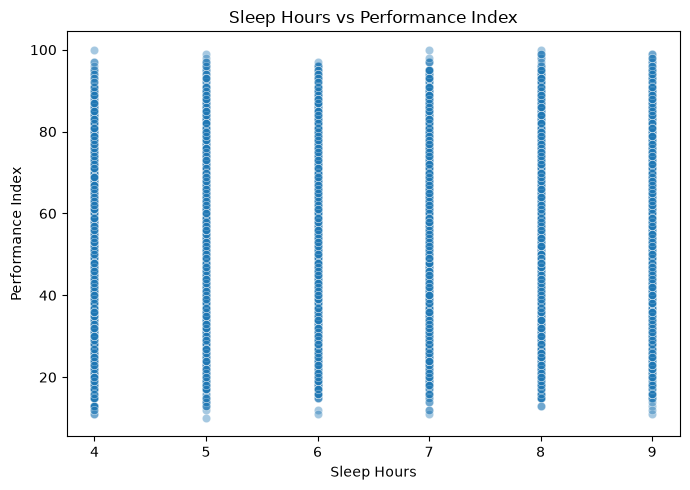

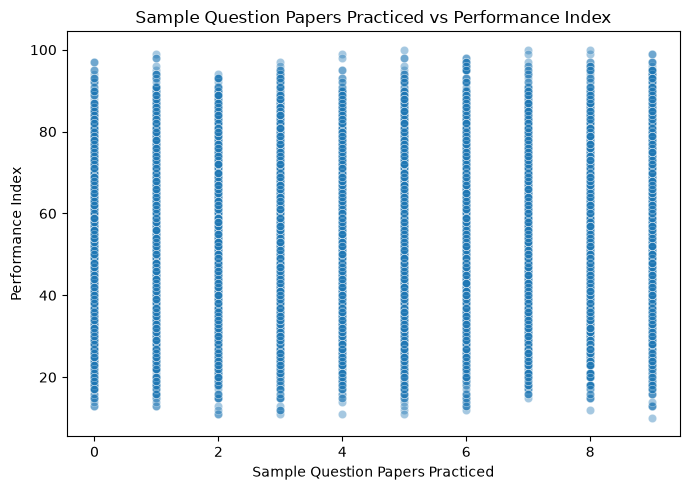

In [50]:
for col in features:
    plt.figure(figsize=(7,5))
    sns.scatterplot(data=df,x=col,y=target,alpha=0.4)
    
    plt.title(f"{col} vs {target}")
    plt.tight_layout()
    plt.show()

## Oservations
1. Hours Studied vs Performance Index: A positive association is visible.Higher study-hour categories generally show higher Performance Index values, although considerable variation exists within each category.
2. Previous Scores vs Performance Index: A strong, approximately linear positive association is visible. Higher previous scores are generally associated with higher Performance Index values.
3. Sleep Hours vs Performance Index: The plot shows substantial overlap across sleep-hour categories, with no clearly visible increasing or decreasing trend.
4. Sample Question Papers Practiced vs Performance Index: Performance Index values vary widely across practice-paper categories. No strong visual trend is apparent from the scatter plot alone.

### Conclusion

Previous Scores shows the clearest positive relationship with Performance Index among the features examined. Hours Studied also shows a positive association, while the relationships involving Sleep Hours and Sample Question Papers Practiced are less visually apparent.

These are preliminary visual observations. Correlation analysis, group-wise summaries, and regression evaluation are required before drawing stronger conclusions about predictive usefulness.

## Correlation Analysis

### Objective 
To measure the direction and strength of linear relationships between numerical features and the target variable, Performance Index.


In [51]:
num_col = df.select_dtypes(include=['number'])

correlation_matrix = num_col.corr()

# Display correlation with target
correlation_matrix["Performance Index"].sort_values(
    ascending=False
)

correlation_matrix

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000000,-0.010676,0.002131,0.015740,0.375332
Previous Scores,-0.010676,1.000000,0.007975,0.008719,0.915135
Sleep Hours,0.002131,0.007975,1.000000,0.004907,0.050352
Sample Question Papers Practiced,0.015740,0.008719,0.004907,1.000000,0.043436
Performance Index,0.375332,0.915135,0.050352,0.043436,1.000000


### Key Observation
1. Previous Score: Show a very positive correlation with Performance Index (0.9151).
2. Hours Studied: Shows a positive correlation with performance Index (r=0.3753). Indicate Moderate linear association.
3. Sleep Hours: Shows a very weak positive linear correlation with Performance Index(r = 0.05035).
4. Sample Paper: Show a very weak positive linear correlation with Performance Index (r = 0.0433).

### Conclusion 
Previous Score has the strongest linear association with Performance Index among the analyzed features. Hours Studied also shows a positive accosiation, while Sleep Hours and Sample Question Paper Practiced have correlation close to zero.

Correlation does not establish causation or independently determine feture importance. Further analysis and model evalution are required to assess the predictive usefulness of each feature.

## Outlier Analysis

### Objective 
To identify potential outliers in numerical features using boxplots and the interquartile Range(IQR) method.

### Why is this important?
Outliers can influence statistical summaries and certain machine learning models. Identifying them helps us decide whether further investigation or preprocessing is required.

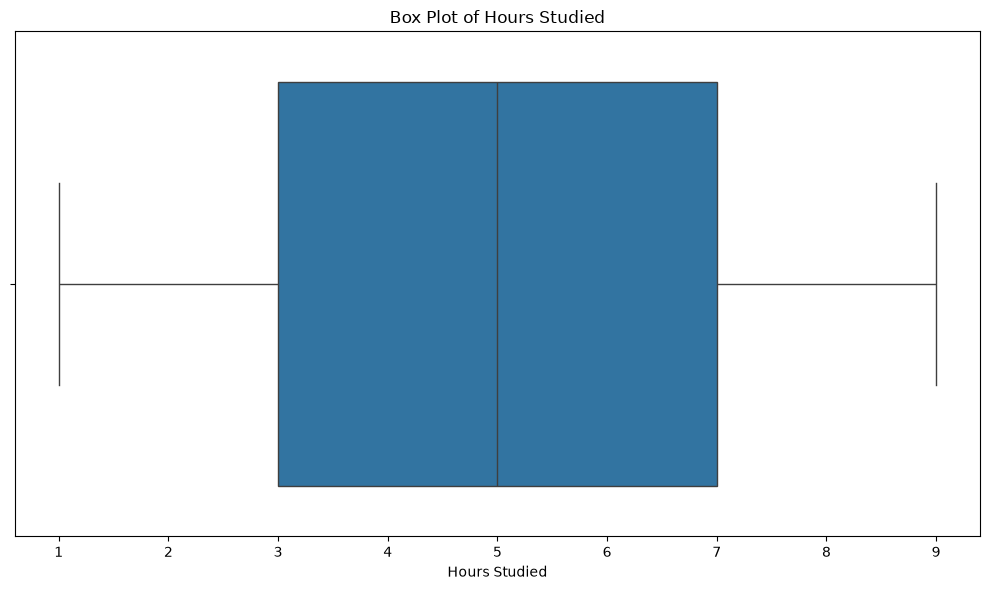

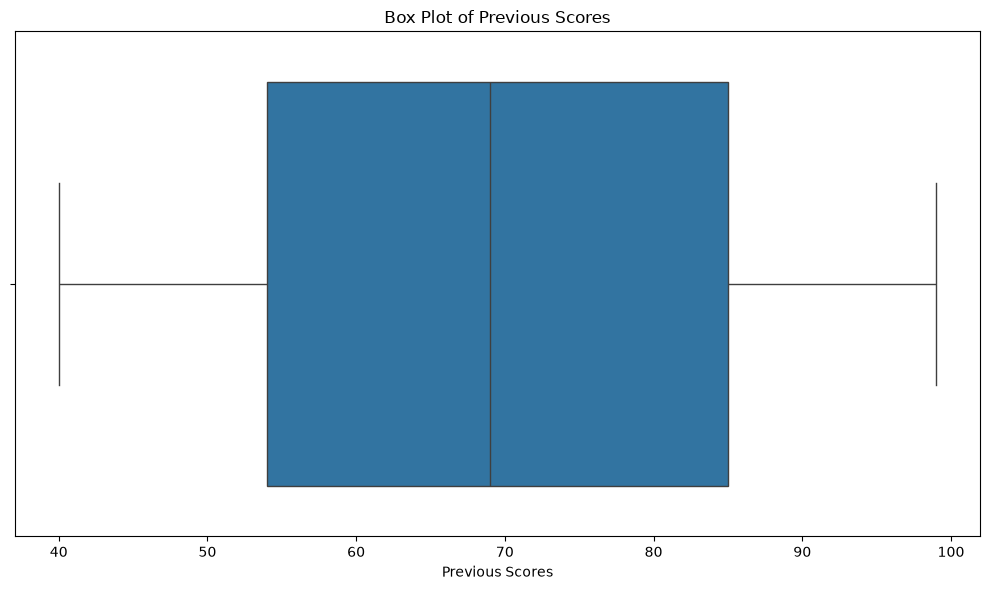

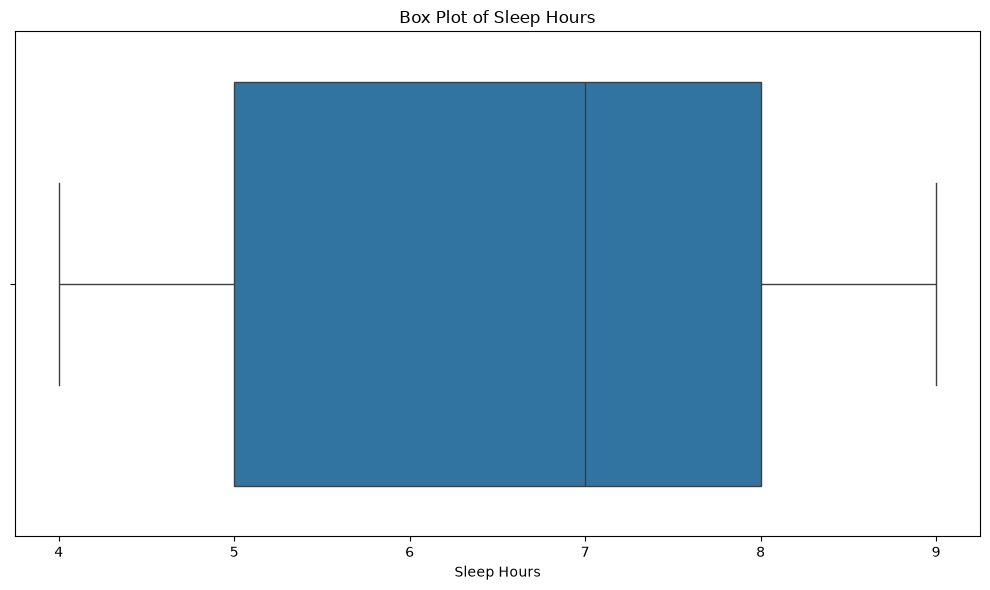

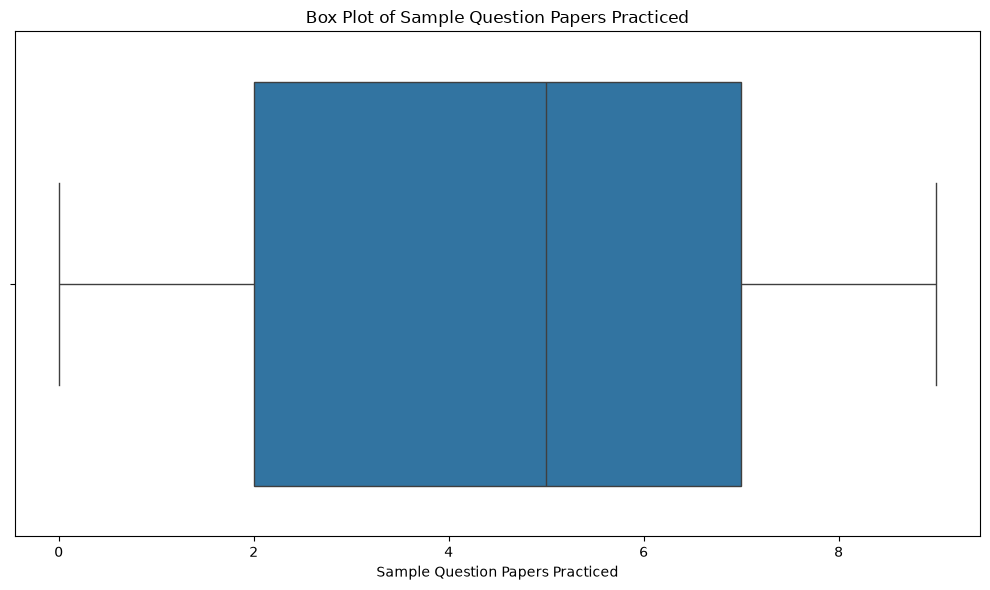

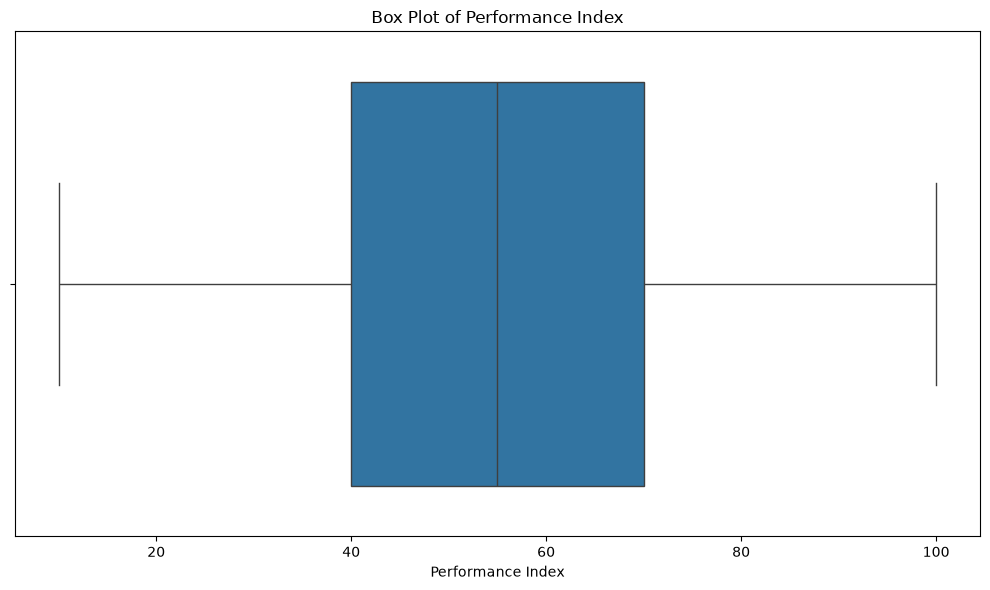

In [52]:
for col in num_col:
    plt.figure(figsize=(10,6))
    sns.boxplot(x=df[col])
    
    plt.title(f"Box Plot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [53]:
outliers =[]

for col in num_col:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    
    outlier_count = ((df[col] < lower)|(df[col]>upper)).sum()
    
    outliers.append({
        'Feature':col,
        'Q1':Q1,
        'Q3':Q3,
        "IQR":IQR,
        'Lower Bound':lower,
        'Upper Bound':upper,
        'Outlier Counts':outlier_count,
        'Outlier Percentage':round(outlier_count / len(df)*100,2)
    })
    
outliers_sum = pd.DataFrame(outliers)
outliers_sum

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Counts,Outlier Percentage
0,Hours Studied,3.0,7.0,4.0,-3.0,13.0,0,0.0
1,Previous Scores,54.0,85.0,31.0,7.5,131.5,0,0.0
2,Sleep Hours,5.0,8.0,3.0,0.5,12.5,0,0.0
3,Sample Question Papers Practiced,2.0,7.0,5.0,-5.5,14.5,0,0.0
4,Performance Index,40.0,70.0,30.0,-5.0,115.0,0,0.0


## Conclusion

The Interquartile Range (IQR) method was used to identify potential outliers in all numerical features.

### Key Findings

* No observations were flagged as outliers in Hours Studied.
* No observations were flagged as outliers in Previous Scores.
* No observations were flagged as outliers in Sleep Hours.
* No observations were flagged as outliers in Sample Question Papers Practiced.
* No observations were flagged as outliers in Performance Index.

The outlier count was zero for all five numerical features under the 1.5 × IQR rule.

### Decision

No outlier removal or outlier treatment is required based on the current IQR analysis.

However, this result does not guarantee that every observation is valid. Domain-specific checks should still be performed to identify impossible values, data-entry errors, or other data-quality issues.


## 8. Feature–Target Analysis

### Objective

To examine how the average Performance Index varies across different values or categories of the input features.

In [54]:
for col in features:
    summary = (df.groupby(col)['Performance Index'].agg(['mean','median','count']).round(2))
    print(f"\nPerformance Index by {col}")
    display(summary)


Performance Index by Hours Studied


,mean,median,count
Hours Studied,,,
1,43.98,44.0,1133
2,46.45,46.0,1077
3,49.76,50.0,1110
4,52.78,53.0,1071
5,55.50,55.0,1069
6,58.48,59.0,1122
7,60.22,60.0,1118
8,64.18,64.0,1074
9,65.81,65.0,1099



Performance Index by Previous Scores


,mean,median,count
Previous Scores,,,
40,24.53,25.0,171
41,27.19,27.0,163
42,26.91,27.0,166
43,28.81,29.0,165
44,29.53,29.0,170
45,30.95,32.0,151
46,31.10,32.0,161
47,33.88,35.0,171
48,32.54,33.0,168



Performance Index by Extracurricular Activities


,mean,median,count
Extracurricular Activities,,,
No,54.72,55.0,4986
Yes,55.72,55.0,4887



Performance Index by Sleep Hours


,mean,median,count
Sleep Hours,,,
4,53.69,54.0,1605
5,54.74,55.0,1580
6,54.71,54.0,1645
7,55.27,55.0,1653
8,55.95,56.0,1784
9,56.85,57.0,1606



Performance Index by Sample Question Papers Practiced


,mean,median,count
Sample Question Papers Practiced,,,
0,52.95,53.0,937
1,54.69,55.0,969
2,55.14,55.0,917
3,55.27,55.0,1020
4,54.12,53.0,945
5,55.30,55.0,1018
6,56.18,56.0,1046
7,55.89,56.0,967
8,55.49,55.0,1016


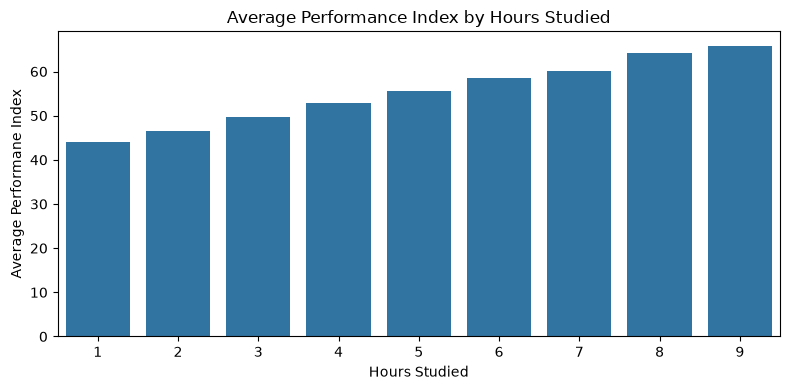

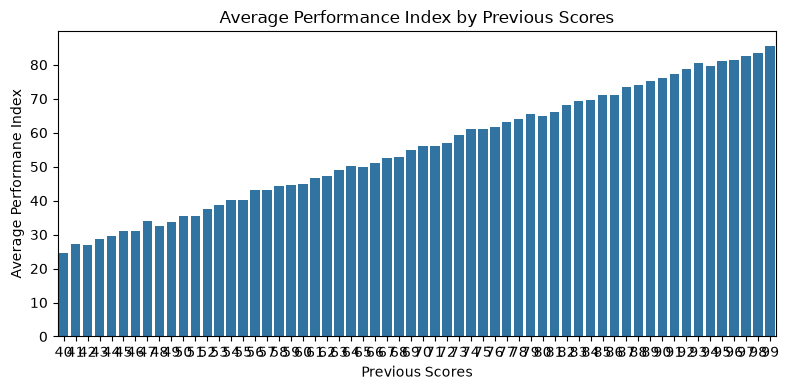

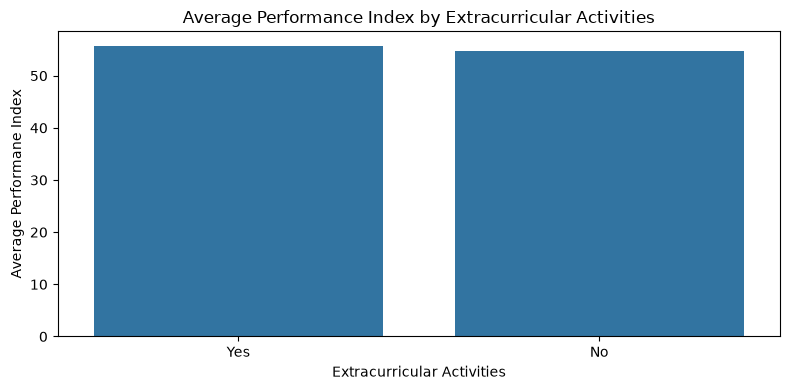

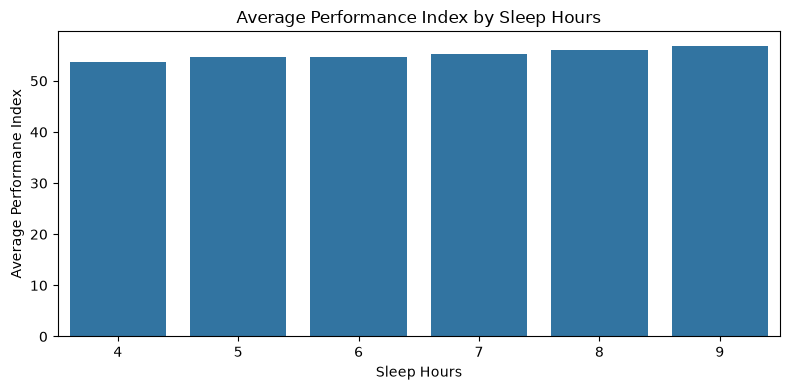

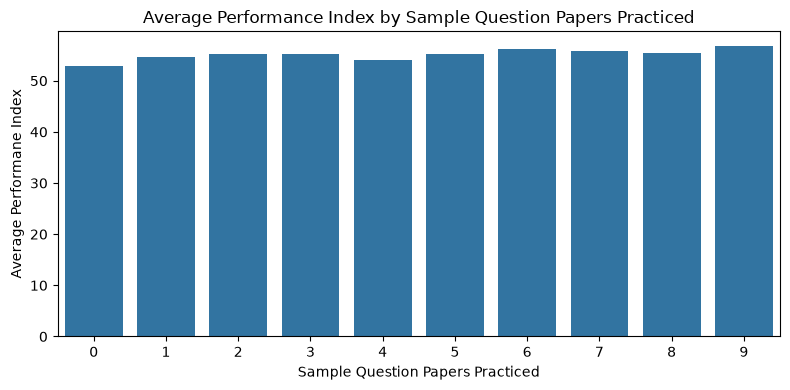

In [55]:
for col in features:
    plt.figure(figsize=(8,4))
    
    sns.barplot(data=df,x=col,y=target,estimator='mean',errorbar=None)
    
    plt.title(f"Average Performance Index by {col}")
    plt.xlabel(col)
    plt.ylabel("Average Performane Index")
    
    plt.tight_layout()
    plt.show()



### Key Findings

1. **Hours Studied:** Average Performance Index increases consistently as study hours increase, indicating a positive association.

2. **Previous Scores:** Average Performance Index increases strongly and approximately linearly with Previous Scores. This feature shows the clearest relationship with the target among the analyzed features.

3. **Extracurricular Activities:** The average Performance Index differs only slightly between the Yes and No categories. Further statistical analysis is needed to assess the significance of this difference.

4. **Sleep Hours:** Average Performance Index varies only modestly across sleep-hour categories. The missing bar for the 9-hour category should be investigated before finalizing the interpretation.

5. **Sample Question Papers Practiced:** Average Performance Index varies slightly across practice-paper categories, without a strong overall linear trend.

### Conclusion

Previous Scores and Hours Studied show the clearest positive relationships with Performance Index. The relationships involving Sleep Hours, Sample Question Papers Practiced, and Extracurricular Activities appear weaker in the current visual analysis.

These findings describe associations, not causal effects. Feature usefulness will be assessed further during model training and evaluation.


## 9. Correlation Heatmap Analysis

### Objective

To visualize the direction and strength of linear relationships between numerical features and the target variable, Performance Index.

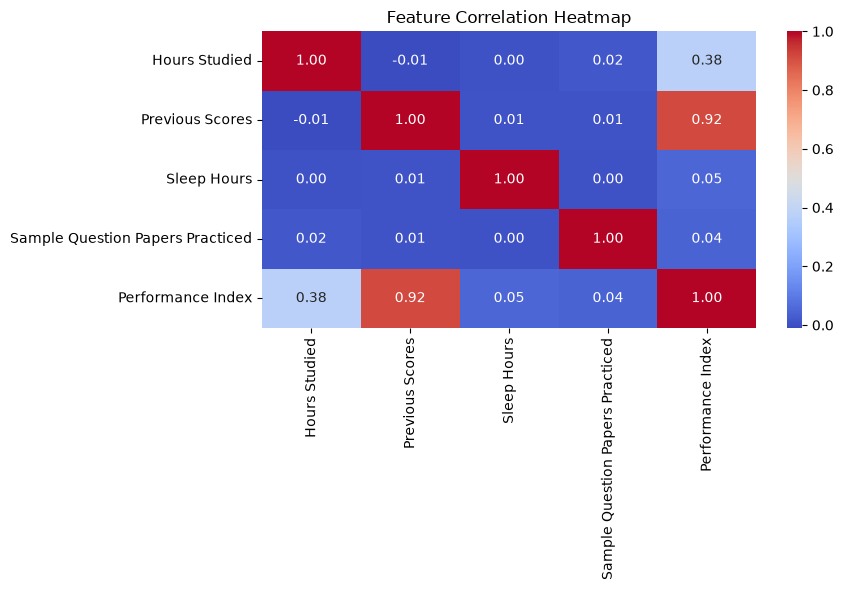

In [56]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    num_col.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### Key Findings

1. Previous Scores has the strongest positive correlation with Performance Index (r ≈ 0.92).
2. Hours Studied has a moderate positive correlation with Performance Index (r ≈ 0.37).
3. Sleep Hours and Sample Question Papers Practiced have very weak linear correlations with Performance Index.
4. The numerical input features show no strong pairwise linear correlations in the displayed matrix.

### Conclusion

Previous Scores and Hours Studied show the strongest linear associations with the target among the numerical features examined. The predictive usefulness of the remaining features will be assessed during model training and evaluation.

Correlation does not establish causation, and a weak Pearson correlation does not rule out nonlinear relationships.


## 10. Categorical Feature Analysis

### Objective

To examine the distribution of the categorical feature Extracurricular Activities and compare Performance Index across its categories.




In [57]:
print(df["Extracurricular Activities"].value_counts())

print("\nCategory Percentages:")
print(
    df["Extracurricular Activities"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Extracurricular Activities
No     4986
Yes    4887
Name: count, dtype: int64

Category Percentages:
Extracurricular Activities
No     50.5
Yes    49.5
Name: proportion, dtype: float64


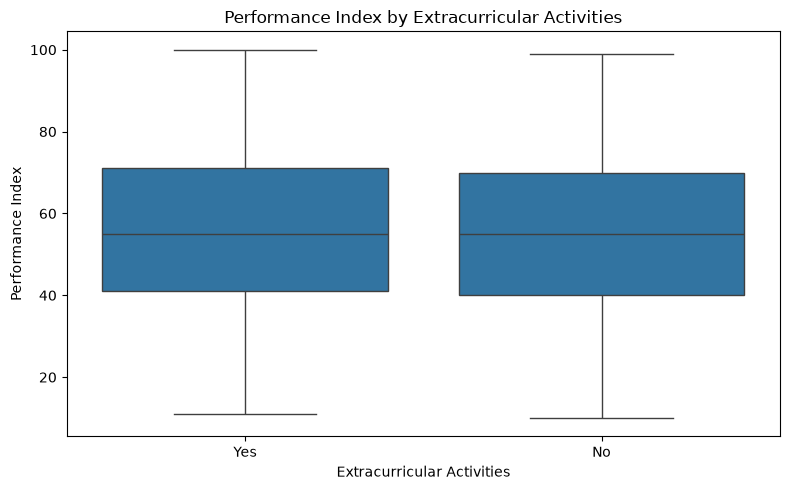

In [58]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Extracurricular Activities",
    y="Performance Index"
)

plt.title("Performance Index by Extracurricular Activities")
plt.xlabel("Extracurricular Activities")
plt.ylabel("Performance Index")

plt.tight_layout()
plt.show()

### Key Findings

**1. Category Distribution**

* No: 4986 observations (50.5%).
* Yes: 4887 observations (49.5%).
* Both categories are represented in approximately equal proportions.

**2. Performance Index Distribution**

* Both categories have approximately the same median Performance Index.
* Their first and third quartiles are also similar.
* The distributions overlap substantially, with no major visual difference between the groups.

### Conclusion

Extracurricular Activities is a reasonably balanced categorical feature. The box plot does not reveal a substantial difference in Performance Index distributions between the Yes and No groups.

This conclusion is based on visual inspection; it does not establish statistical equivalence or prove the absence of an effect.

# 11. Final EDA Summary

## Dataset Overview

The dataset contains 9873 observations and six columns. The target variable is Performance Index.

## Data Quality

* Missing values: None detected.
* Duplicate rows: 127 were identified and removed during data cleaning.
* IQR-based outlier analysis: No observations were flagged as outliers across the numerical features.

## Major Findings

1. Previous Scores has a very strong positive correlation with Performance Index (approximately 0.92).
2. Hours Studied has a moderate positive correlation with Performance Index (approximately 0.37).
3. Sleep Hours and Sample Question Papers Practiced have very weak Pearson correlations with Performance Index.
4. Extracurricular Activities has approximately balanced categories, and the box plot shows similar Performance Index distributions across the two groups.
5. The dataset's numerical input features do not show strong pairwise linear correlations in the analyzed matrix.

## Next Steps

* Separate input features and target variable.
* Split the data into training and testing sets.
* Build a preprocessing pipeline for numerical and categorical features.
* Train a baseline Linear Regression model.
* Evaluate predictions using MAE, RMSE, and R².

The above findings are exploratory and will be validated further through model evaluation.
